In [2]:
import os, glob, gc, random, zipfile
import numpy as np
import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from tqdm.auto import tqdm
from IPython.display import display

SEED = 42
N_CASES = 20
ROI_SIZE = (128, 128, 128)
THRESHOLD = 0.5
SHOW_ALL = True   
OUTPUT_DIR = '/kaggle/working/brats_visualizations'
os.makedirs(OUTPUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

DATA_DIR = '/kaggle/input/datasets/ahmedelzayat77/bratsglioma/Training'
STUDENT_WEIGHTS = '/kaggle/input/models/sorensalehi/student-model-brats2023/pytorch/default/1/best_distilled_student.pth'

if not os.path.isdir(DATA_DIR):
    alternatives = glob.glob('/kaggle/input/**/Training', recursive=True)
    alternatives = [p for p in alternatives if os.path.isdir(p)]
    if len(alternatives) == 1: DATA_DIR = alternatives[0]
    else: raise FileNotFoundError(f'DATA_DIR not found: {DATA_DIR}. Candidates: {alternatives[:12]}')
if not os.path.isfile(STUDENT_WEIGHTS):
    matches = glob.glob('/kaggle/input/**/best_distilled_student.pth', recursive=True)
    if len(matches) == 1: STUDENT_WEIGHTS = matches[0]
    else: raise FileNotFoundError(f'Student checkpoint not found. Candidates: {matches[:12]}')
print('Data:', DATA_DIR)
print('Checkpoint:', STUDENT_WEIGHTS)

Device: cuda
Data: /kaggle/input/datasets/ahmedelzayat77/bratsglioma/Training
Checkpoint: /kaggle/input/models/sorensalehi/student-model-brats2023/pytorch/default/1/best_distilled_student.pth


In [3]:
class ParallelConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.embed = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm3d(out_channels),
            nn.LeakyReLU(0.1, inplace=True)
        )
        self.p1 = nn.Sequential(
            nn.Conv3d(out_channels, out_channels, 1, bias=False),
            nn.InstanceNorm3d(out_channels),
            nn.LeakyReLU(0.1, inplace=True)
        )
        self.p2 = nn.Sequential(
            nn.Conv3d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.InstanceNorm3d(out_channels),
            nn.LeakyReLU(0.1, inplace=True)
        )
        self.p3 = nn.Sequential(
            nn.Conv3d(out_channels, out_channels, 5, padding=2, bias=False),
            nn.InstanceNorm3d(out_channels),
            nn.LeakyReLU(0.1, inplace=True)
        )
        self.pool = nn.MaxPool3d(2)

    def forward(self, x):
        feat = self.embed(x)
        o1 = self.pool(self.p1(feat))
        o2 = self.pool(self.p2(feat))
        o3 = self.pool(self.p3(feat))
        return torch.cat([o1, o2, o3], dim=1), feat


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.InstanceNorm3d(out_channels),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv3d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.InstanceNorm3d(out_channels),
            nn.LeakyReLU(0.1, inplace=True)
        )

    def forward(self, x): 
        return self.conv(x)


class LATUPStudent(nn.Module):
    def __init__(self, in_channels=4, out_channels=3, base_filters=16):
        super().__init__()
        self.enc1_pc = ParallelConvBlock(in_channels, base_filters)
        self.enc2 = ConvBlock(base_filters * 3, base_filters * 2)
        self.pool2 = nn.MaxPool3d(2)
        self.enc3 = ConvBlock(base_filters * 2, base_filters * 4)
        self.pool3 = nn.MaxPool3d(2)
        self.bottleneck = ConvBlock(base_filters * 4, base_filters * 8)
        self.up3 = nn.Upsample(scale_factor=2, mode='trilinear', align_corners=True)
        self.dec3 = ConvBlock(base_filters * 8 + base_filters * 4, base_filters * 4)
        self.up2 = nn.Upsample(scale_factor=2, mode='trilinear', align_corners=True)
        self.dec2 = ConvBlock(base_filters * 4 + base_filters * 2, base_filters * 2)
        self.up1 = nn.Upsample(scale_factor=2, mode='trilinear', align_corners=True)
        self.dec1 = ConvBlock(base_filters * 2 + base_filters, base_filters)
        self.out_conv = nn.Conv3d(base_filters, out_channels, kernel_size=1)

    def forward(self, x):
        x1, skip1 = self.enc1_pc(x)
        skip2 = self.enc2(x1)
        x2 = self.pool2(skip2)
        skip3 = self.enc3(x2)
        x3 = self.pool3(skip3)
        x_bot = self.bottleneck(x3)
        d3 = self.dec3(torch.cat([self.up3(x_bot), skip3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), skip2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), skip1], dim=1))
        return self.out_conv(d1)

In [4]:
def load_student_strict(path):
    model = LATUPStudent(in_channels=4, out_channels=3, base_filters=16)
    try:
        ckpt = torch.load(path, map_location='cpu', weights_only=True)
    except TypeError:
        ckpt = torch.load(path, map_location='cpu')
    if isinstance(ckpt, dict):
        state = next((ckpt[k] for k in ('model_state_dict','state_dict','model') if k in ckpt), ckpt)
    else: state = ckpt
    if not isinstance(state, dict): raise TypeError('Checkpoint has no recognizable state_dict')
    clean = {}
    for k, v in state.items():
        if not isinstance(v, torch.Tensor): continue
        while k.startswith('module.') or k.startswith('model.'):
            k = k.split('.',1)[1]
        if k.startswith(('out_conv2.','out_conv3.')): continue
        clean[k] = v
    model.load_state_dict(clean, strict=True)
    return model.to(device).eval().requires_grad_(False)

student = load_student_strict(STUDENT_WEIGHTS)
print('Student weights loaded strictly and successfully.')

Student weights loaded strictly and successfully.


In [5]:
def locate_mod(case_dir, mod):
    # BraTS-GLI naming: -t2f, -t1n, -t1c, -t2w, -seg
    aliases = {'flair':['t2f','flair'], 't1':['t1n','t1'],
               't1ce':['t1c','t1ce'], 't2':['t2w','t2'], 'seg':['seg']}
    files = sorted(glob.glob(os.path.join(case_dir, '*.nii*')))
    for suffix in aliases[mod]:
        matches = [p for p in files if os.path.basename(p).lower().split('.nii')[0].endswith('-'+suffix)]
        if len(matches) == 1: return matches[0]
    return None

def center_crop_or_pad(data, target=ROI_SIZE):
    # data: (C,D,H,W); same center pad/crop as original BraTSDataset
    _, d,h,w = data.shape
    pd,ph,pw = [max(0, t-v) for t,v in zip(target,(d,h,w))]
    if pd or ph or pw:
        data = np.pad(data, ((0,0),(pd//2,pd-pd//2),(ph//2,ph-ph//2),(pw//2,pw-pw//2)))
    _,d,h,w = data.shape
    sd,sh,sw = [(v-t)//2 for v,t in zip((d,h,w),target)]
    return np.ascontiguousarray(data[:,sd:sd+target[0],sh:sh+target[1],sw:sw+target[2]])

def load_case(case_dir):
    mods = []
    for mod in ('flair','t1','t1ce','t2'):
        path = locate_mod(case_dir,mod)
        if path is None: raise FileNotFoundError(f'{mod} missing in {case_dir}')
        vol = nib.load(path).get_fdata(dtype=np.float32)
        nz = vol != 0
        if nz.any():
            vals = vol[nz]
            vol[nz] = (vals - vals.mean())/(vals.std()+1e-8)
        mods.append(vol)
    image = np.transpose(np.stack(mods,axis=0),(0,3,1,2))
    image = center_crop_or_pad(image).astype(np.float32)
    segpath = locate_mod(case_dir,'seg')
    gt = None
    if segpath:
        seg = nib.load(segpath).get_fdata().astype(np.int16)
        # BraTS 2023 GLI: 1=necrotic/non-enhancing core, 2=edema, 3=enhancing tumor
        # also accept legacy ET=4 only if 3 is absent
        labels = set(np.unique(seg).tolist())
        et_label = 4 if 4 in labels and 3 not in labels else 3
        gt = np.stack([(seg>0), np.isin(seg,[1,et_label]), (seg==et_label)],axis=0).astype(np.uint8)
        gt = center_crop_or_pad(np.transpose(gt,(0,3,1,2)))
    return image,gt

def nested_masks(binary):
    wt,tc,et = [x.astype(bool) for x in binary]
    tc = tc & wt; et = et & tc
    return np.stack([wt,tc,et])

def region_map(masks):
    wt,tc,et = nested_masks(masks)
    result = np.zeros(wt.shape,dtype=np.uint8)
    result[wt] = 2  # edema / WT outside core (green)
    result[tc] = 1  # tumor core outside ET (red)
    result[et] = 3  # enhancing tumor (yellow)
    return result

@torch.inference_mode()
def predict(image):
    x = torch.from_numpy(image[None]).to(device)
    logits = student(x)
    if isinstance(logits,(tuple,list)): logits=logits[0]
    pred = (torch.sigmoid(logits)[0] >= THRESHOLD).cpu().numpy()
    return nested_masks(pred)

def dice(pred,gt):
    a,b=pred.astype(bool),gt.astype(bool)
    den=a.sum()+b.sum()
    return float(2*np.logical_and(a,b).sum()/den) if den else 1.0

cases = sorted(p for p in glob.glob(os.path.join(DATA_DIR,'*')) if os.path.isdir(p))
valid_cases = [p for p in cases if all(locate_mod(p,m) for m in ('flair','t1','t1ce','t2','seg'))]
if len(valid_cases) < N_CASES: raise ValueError(f'Only {len(valid_cases)} labeled cases available; need {N_CASES}')
# Random, reproducible sample; not sorted by best performance
selected_cases = random.Random(SEED).sample(valid_cases,N_CASES)
print('Selected',len(selected_cases),'labeled cases')

Selected 20 labeled cases


Creating 20 figures:   0%|          | 0/20 [00:00<?, ?it/s]

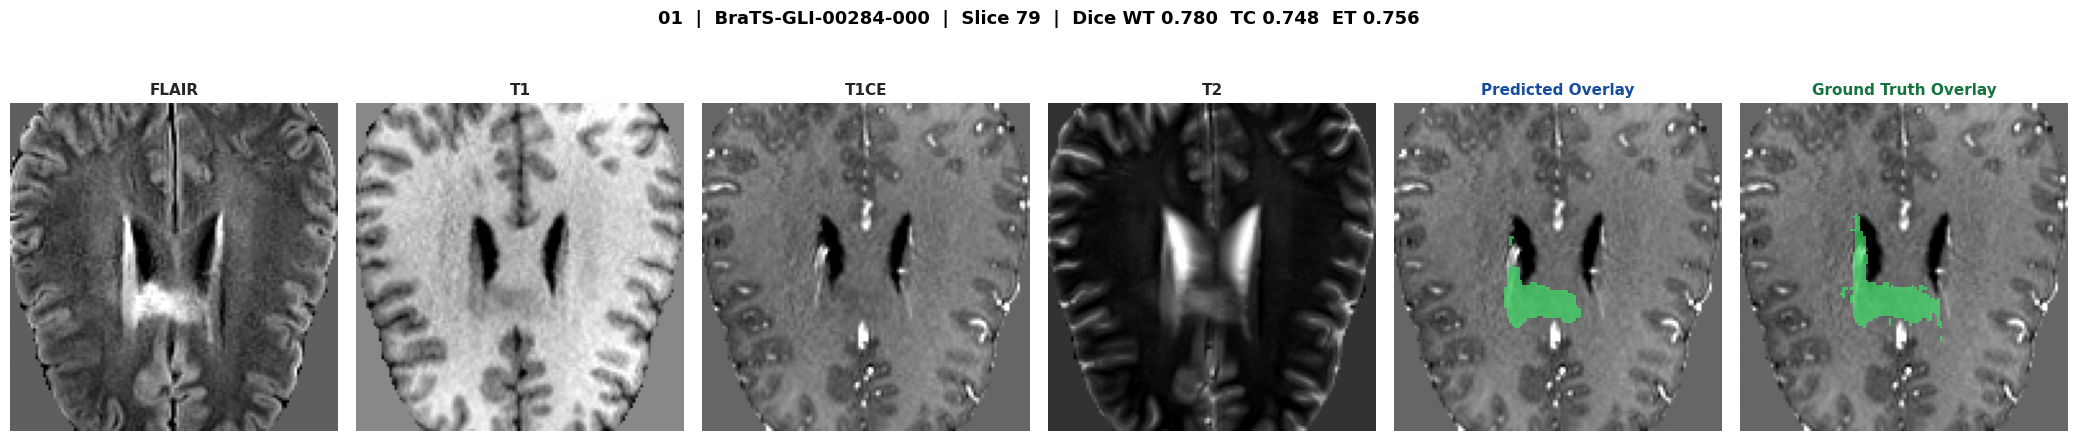

ERROR for BraTS-GLI-00054-000: Empty file: '/kaggle/input/datasets/ahmedelzayat77/bratsglioma/Training/BraTS-GLI-00054-000/BraTS-GLI-00054-000-t2f.nii'
ERROR for BraTS-GLI-00682-000: Empty file: '/kaggle/input/datasets/ahmedelzayat77/bratsglioma/Training/BraTS-GLI-00682-000/BraTS-GLI-00682-000-t2f.nii'
ERROR for BraTS-GLI-00611-000: Empty file: '/kaggle/input/datasets/ahmedelzayat77/bratsglioma/Training/BraTS-GLI-00611-000/BraTS-GLI-00611-000-t2f.nii'


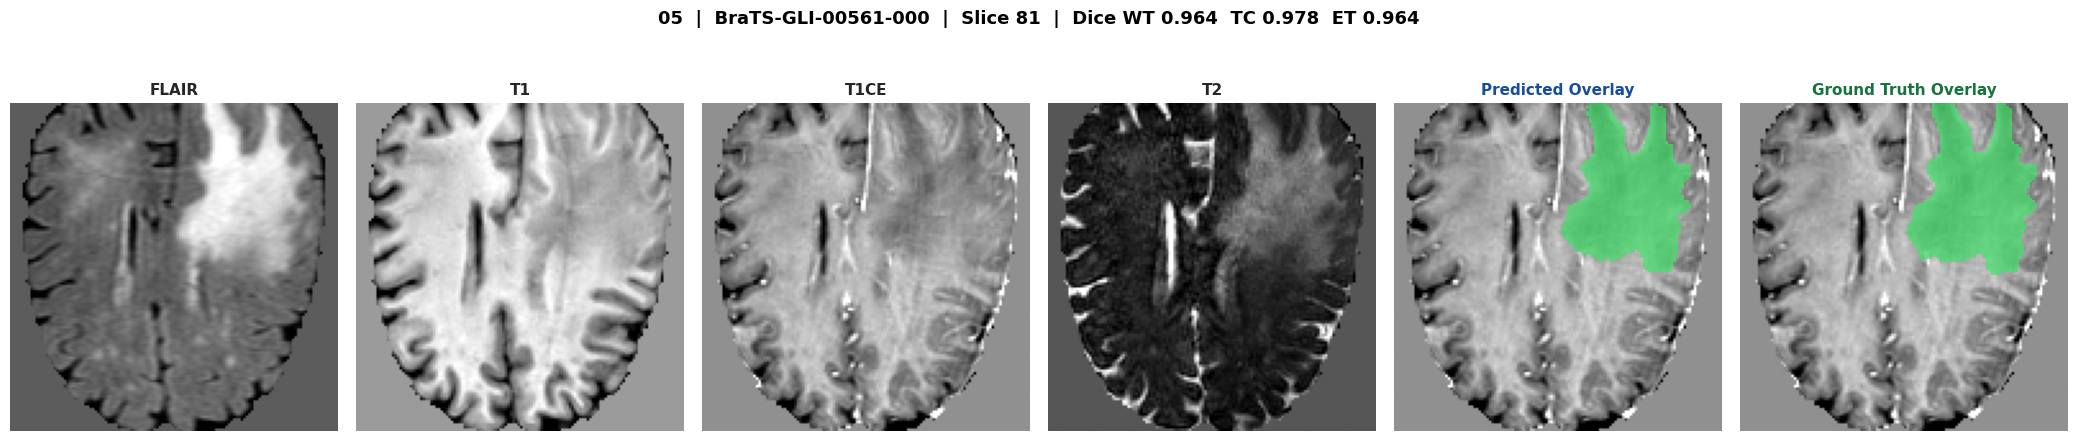

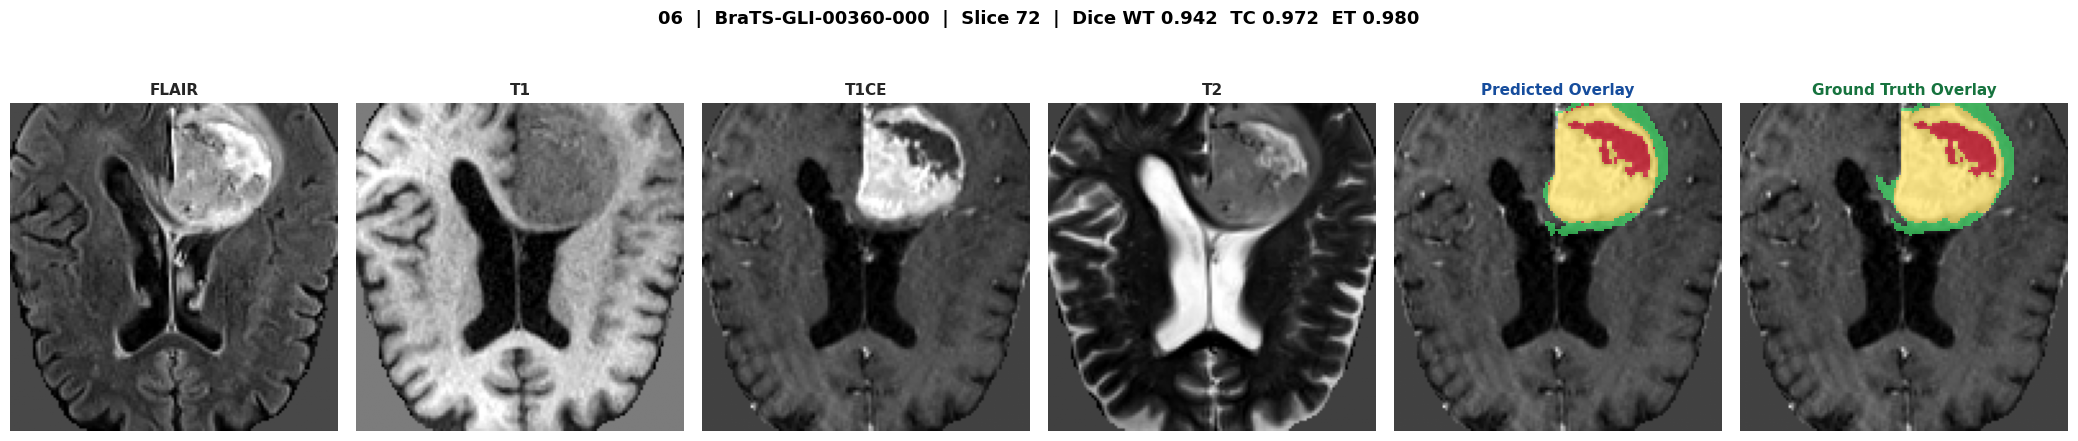

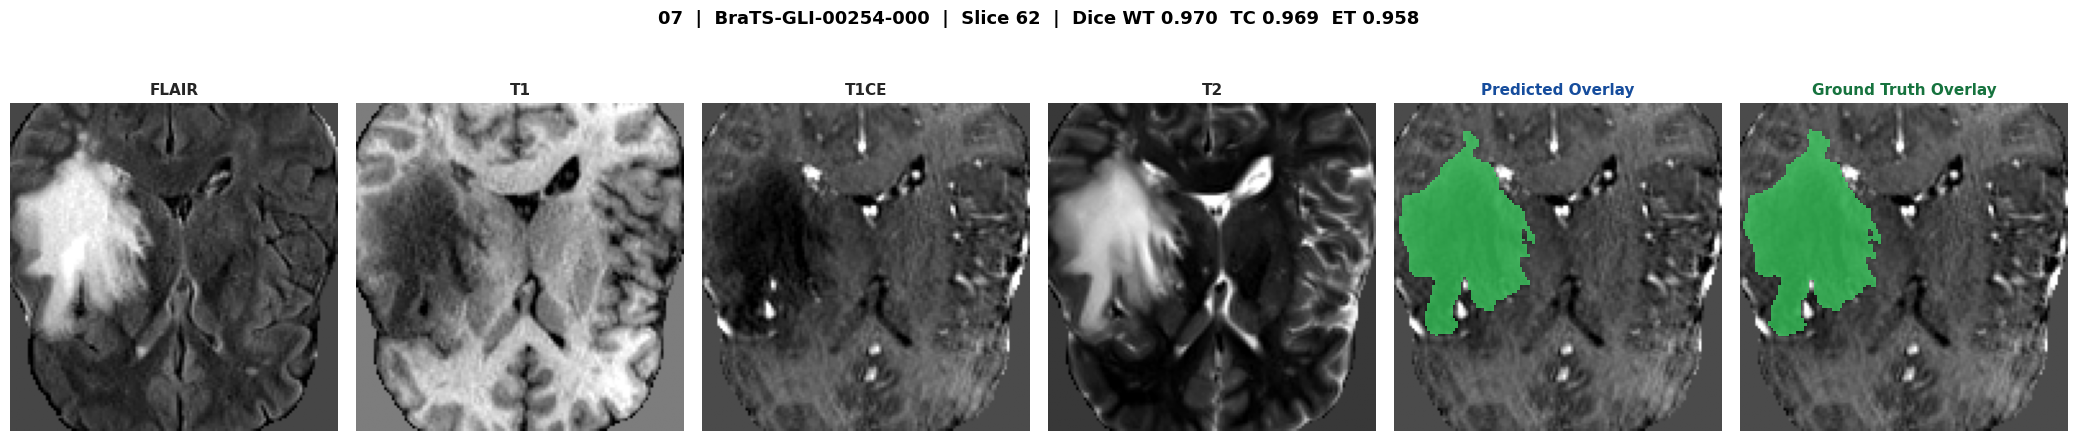

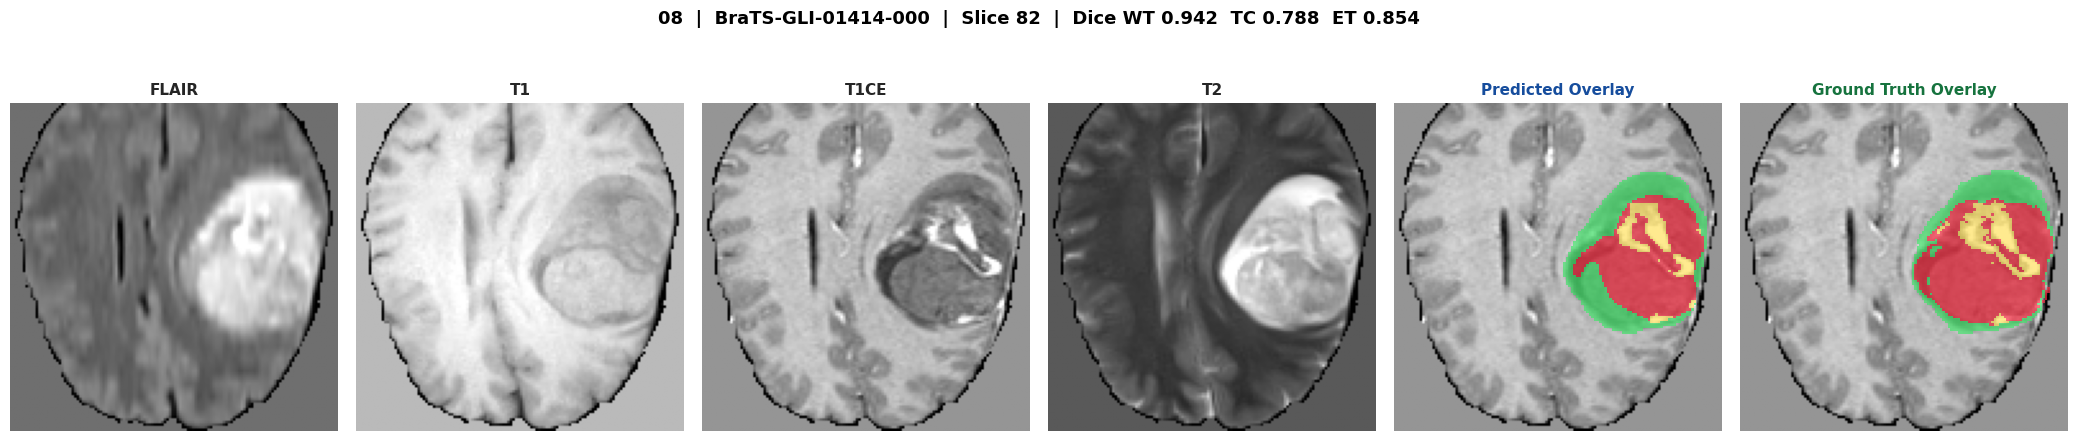

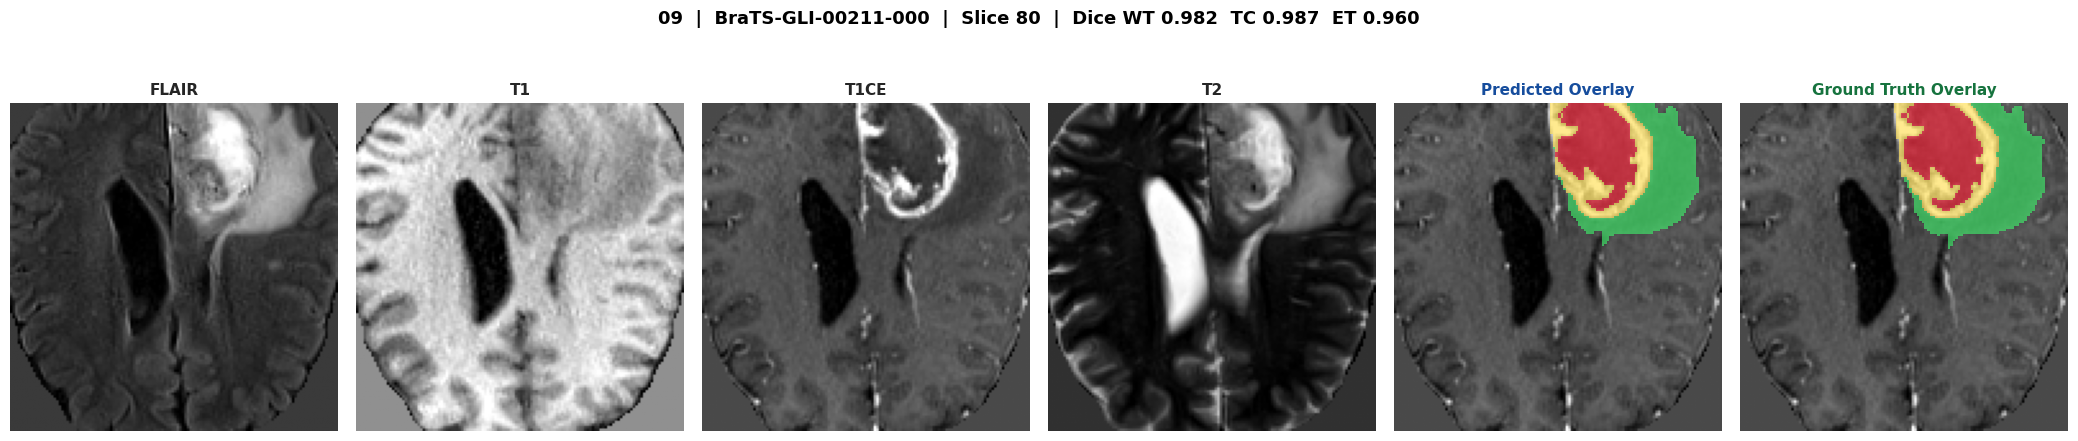

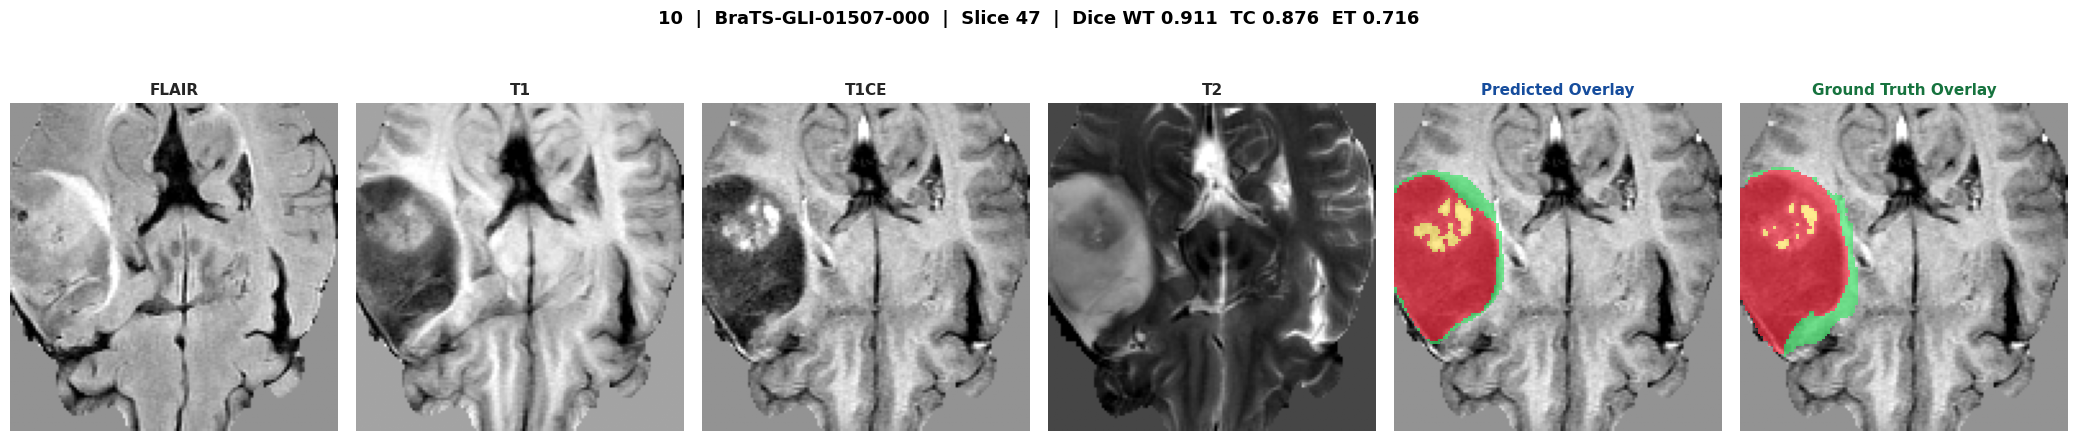

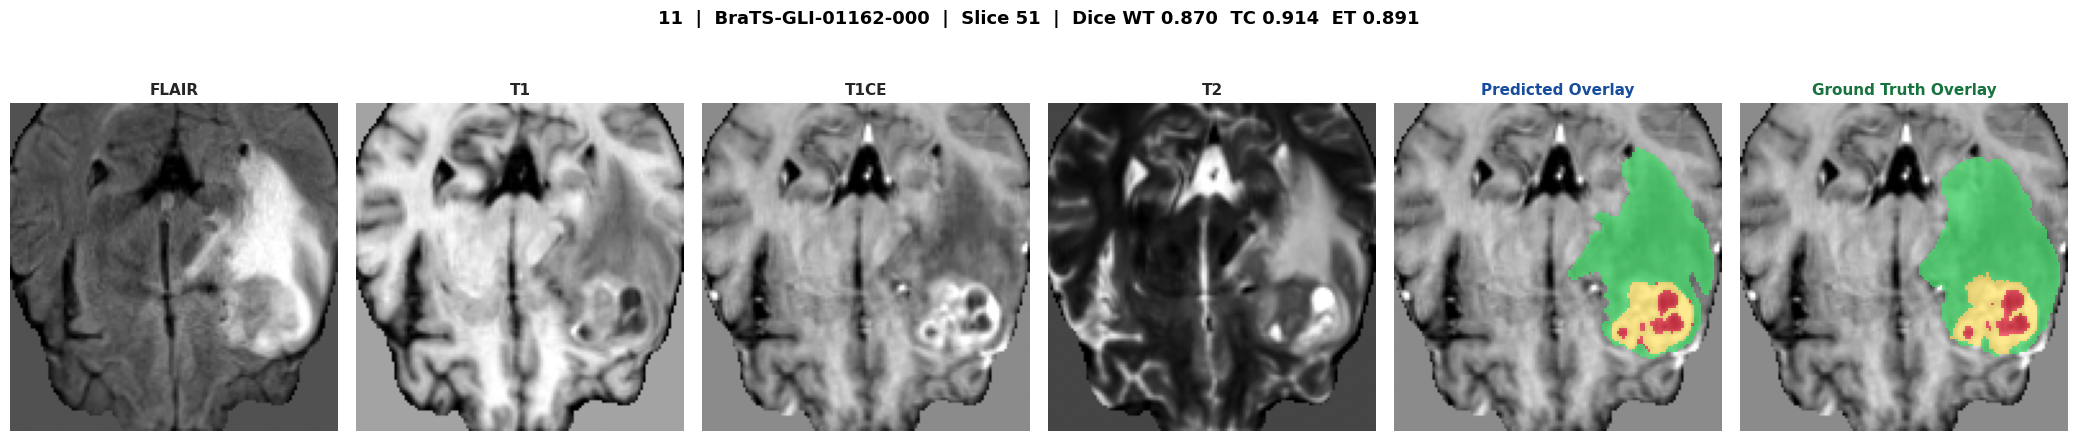

ERROR for BraTS-GLI-00068-000: Empty file: '/kaggle/input/datasets/ahmedelzayat77/bratsglioma/Training/BraTS-GLI-00068-000/BraTS-GLI-00068-000-t2f.nii'
ERROR for BraTS-GLI-00062-000: Empty file: '/kaggle/input/datasets/ahmedelzayat77/bratsglioma/Training/BraTS-GLI-00062-000/BraTS-GLI-00062-000-t2f.nii'


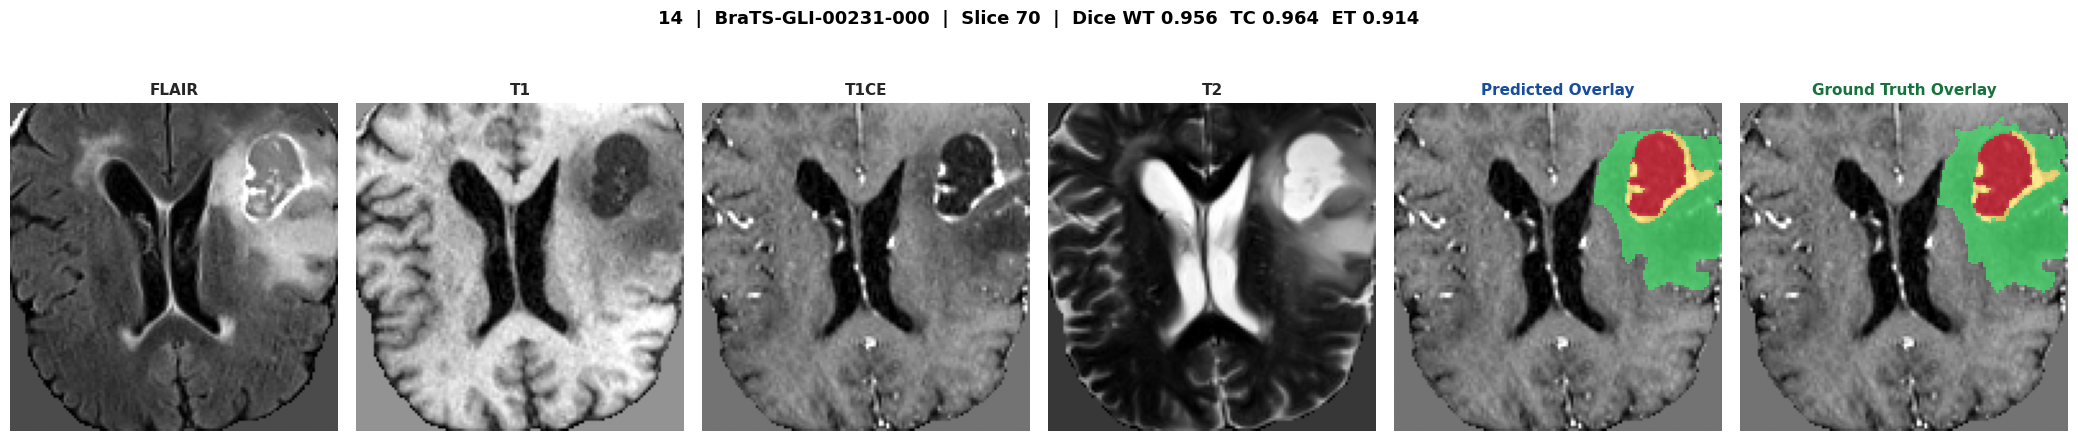

ERROR for BraTS-GLI-00554-000: Empty file: '/kaggle/input/datasets/ahmedelzayat77/bratsglioma/Training/BraTS-GLI-00554-000/BraTS-GLI-00554-000-t2f.nii'


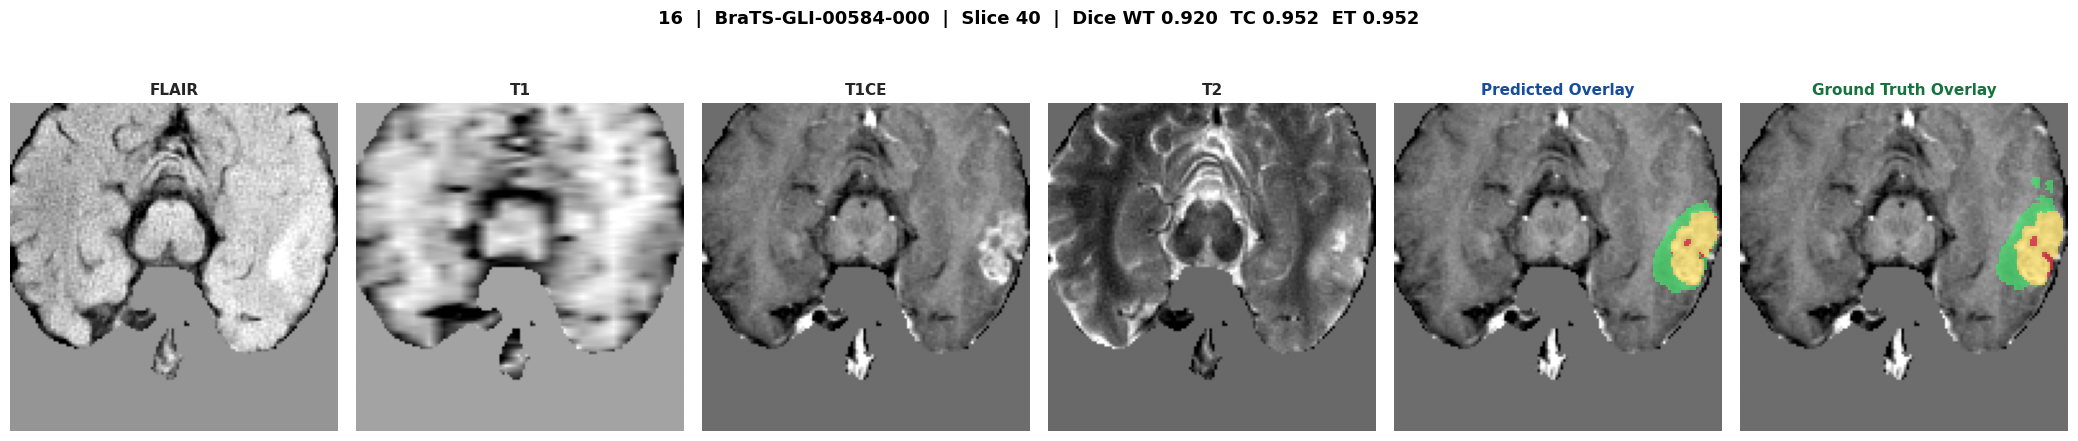

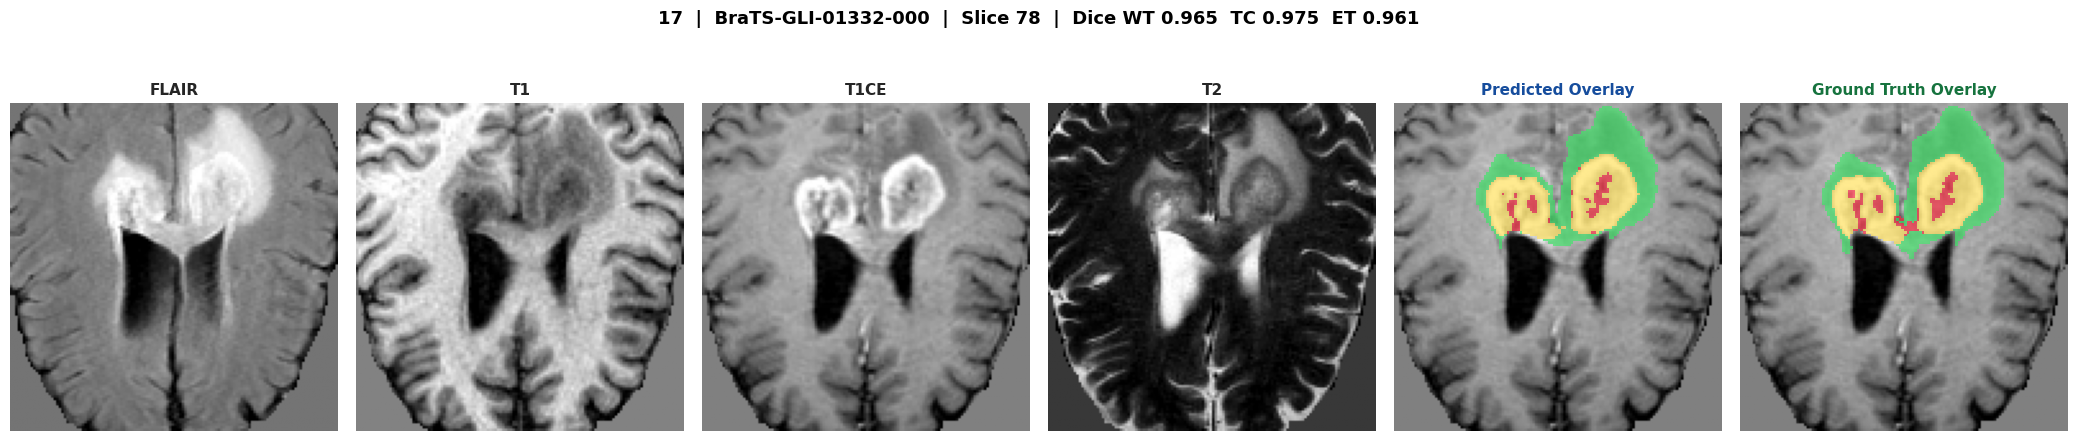

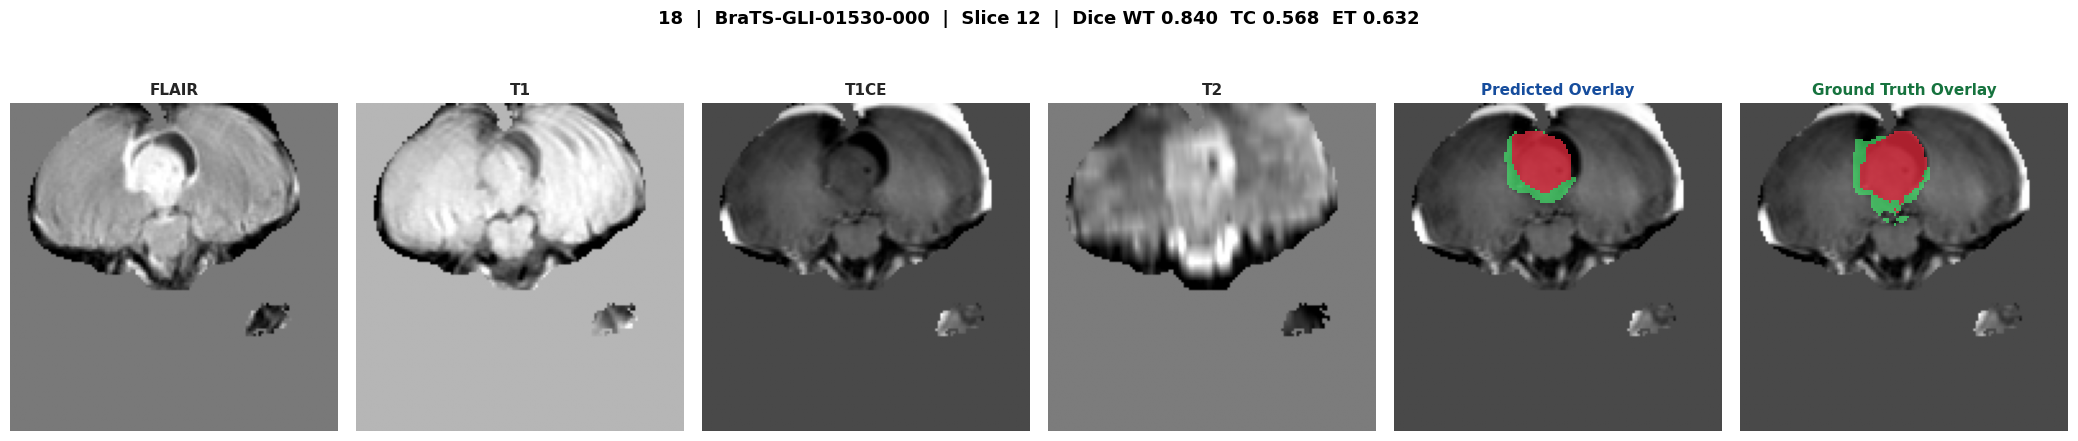

ERROR for BraTS-GLI-00058-000: Empty file: '/kaggle/input/datasets/ahmedelzayat77/bratsglioma/Training/BraTS-GLI-00058-000/BraTS-GLI-00058-000-t2f.nii'


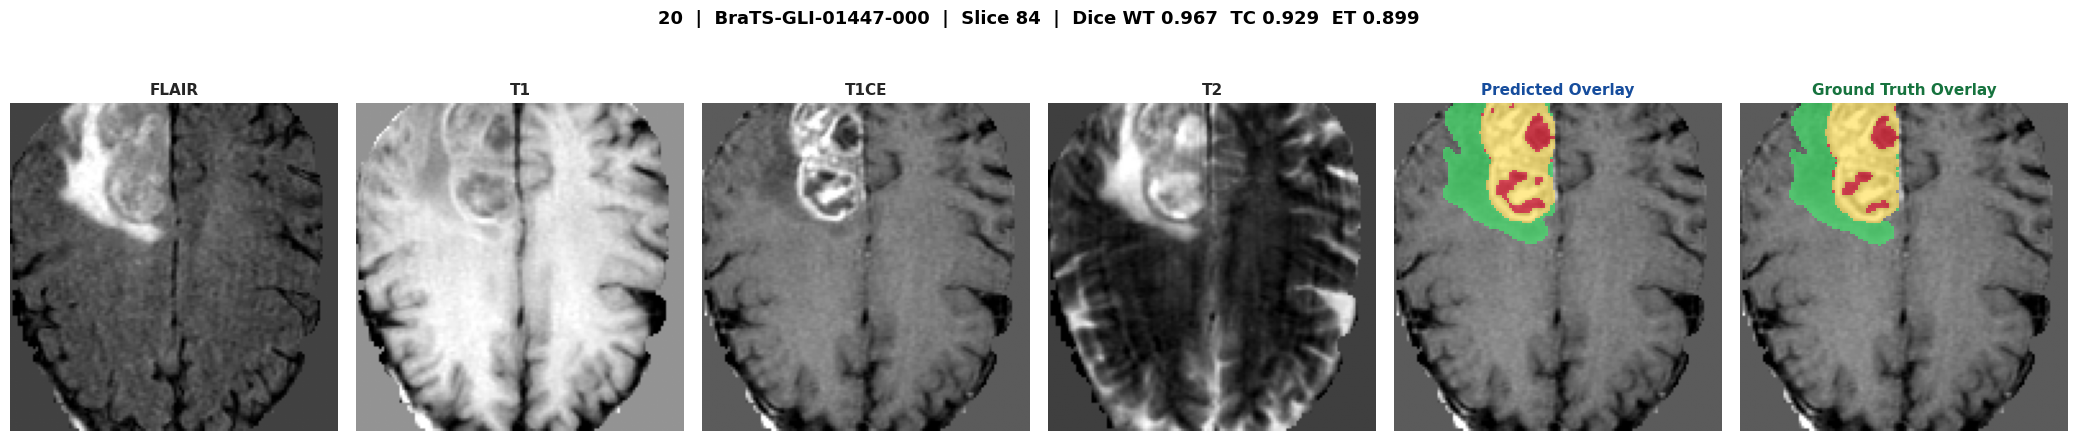

Figures created: 13 of 20


,case,dice_wt,dice_tc,dice_et
0,BraTS-GLI-00284-000,0.779511,0.748128,0.755662
1,BraTS-GLI-00561-000,0.963871,0.978097,0.963728
2,BraTS-GLI-00360-000,0.942212,0.972032,0.980149
3,BraTS-GLI-00254-000,0.969872,0.969241,0.958327
4,BraTS-GLI-01414-000,0.941522,0.788061,0.853749
5,BraTS-GLI-00211-000,0.982459,0.986931,0.960022
6,BraTS-GLI-01507-000,0.910773,0.876076,0.716248
7,BraTS-GLI-01162-000,0.869604,0.914354,0.890724
8,BraTS-GLI-00231-000,0.955609,0.964425,0.913619
9,BraTS-GLI-00584-000,0.920225,0.952459,0.951705


In [6]:
CMAP = ListedColormap(['#000000','#ff3045','#42e66b','#ffe15a'])
NORM = BoundaryNorm([-.5,.5,1.5,2.5,3.5],CMAP.N)
TITLES=['FLAIR','T1','T1CE','T2','Predicted Overlay','Ground Truth Overlay']

def show_overlay(ax,base,label_map):
    ax.imshow(np.rot90(base),cmap='gray',vmin=np.percentile(base,1),vmax=np.percentile(base,99.5))
    layer=np.ma.masked_equal(np.rot90(label_map),0)
    ax.imshow(layer,cmap=CMAP,norm=NORM,alpha=.68,interpolation='nearest')

def plot_six(case_name,image,pred,gt,idx,show=True):
    # Choose slice by GT tumor area, same as earlier training visualization
    z=int(np.argmax(gt[0].sum(axis=(1,2))))
    predmap=region_map(pred[:,z]); gtmap=region_map(gt[:,z])
    fig,axes=plt.subplots(1,6,figsize=(21,4.4),facecolor='white')
    for j in range(4):
        im=image[j,z]; axes[j].imshow(np.rot90(im),cmap='gray',vmin=np.percentile(im,1),vmax=np.percentile(im,99.5))
    show_overlay(axes[4],image[2,z],predmap)
    show_overlay(axes[5],image[2,z],gtmap)
    for j,ax in enumerate(axes):
        ax.set_title(TITLES[j],fontsize=11,fontweight='bold',color=('#164d9d' if j==4 else '#16733e' if j==5 else '#252525'))
        ax.axis('off')
    scores=[dice(pred[k],gt[k]) for k in range(3)]
    fig.suptitle(f'{idx:02d}  |  {case_name}  |  Slice {z}  |  Dice WT {scores[0]:.3f}  TC {scores[1]:.3f}  ET {scores[2]:.3f}',fontsize=13,fontweight='bold',y=1.03)
    fig.subplots_adjust(left=.01,right=.99,bottom=.01,top=.88,wspace=.055)
    out=os.path.join(OUTPUT_DIR,f'{idx:02d}_{case_name}_six_panel.png')
    fig.savefig(out,dpi=300,bbox_inches='tight',facecolor='white')
    if show: plt.show()
    plt.close(fig)
    return scores,z,out

import pandas as pd
records=[]
for idx,case in enumerate(tqdm(selected_cases,desc='Creating 20 figures'),1):
    name=os.path.basename(case)
    try:
        image,gt=load_case(case)
        if gt is None: raise ValueError('Ground truth unavailable')
        pred=predict(image)
        scores,z,out=plot_six(name,image,pred,gt,idx,SHOW_ALL)
        records.append({'case':name,'slice':z,'dice_wt':scores[0],'dice_tc':scores[1],'dice_et':scores[2],'figure':out})
    except Exception as e:
        print(f'ERROR for {name}: {e}')
    finally:
        gc.collect()
        if device.type=='cuda': torch.cuda.empty_cache()
results=pd.DataFrame(records)
results.to_csv(os.path.join(OUTPUT_DIR,'dice_20_cases.csv'),index=False)
print('Figures created:',len(results),'of',N_CASES)
display(results[['case','dice_wt','dice_tc','dice_et']])
if len(results)!=N_CASES: print('WARNING: Not all 20 cases completed. Review errors above.')

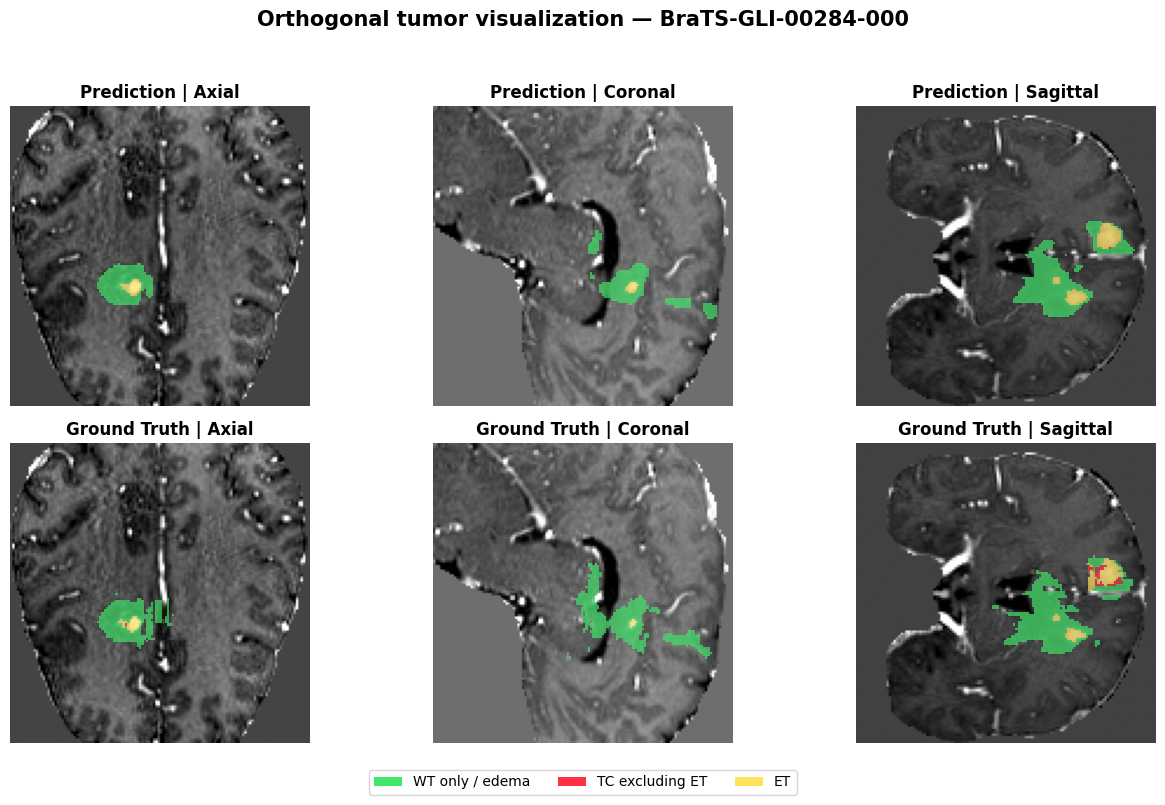

In [7]:
# Select a representative case (first sampled case) and show orthogonal planes.
case=selected_cases[0]
image,gt=load_case(case); pred=predict(image)
# WT centroid for meaningful views
coords=np.argwhere(gt[0])
center=np.rint(coords.mean(axis=0)).astype(int) if len(coords) else np.array(ROI_SIZE)//2
z,y,x=center
pm=region_map(pred); gm=region_map(gt)
fig,axs=plt.subplots(2,3,figsize=(13,8),facecolor='white')
for row,(name,mask) in enumerate([('Prediction',pm),('Ground Truth',gm)]):
    for col,(axis,index,view) in enumerate([(0,z,'Axial'),(1,y,'Coronal'),(2,x,'Sagittal')]):
        bg=np.take(image[2],index,axis=axis)
        seg=np.take(mask,index,axis=axis)
        show_overlay(axs[row,col],bg,seg)
        axs[row,col].set_title(f'{name} | {view}',fontweight='bold')
        axs[row,col].axis('off')
fig.suptitle(f'Orthogonal tumor visualization — {os.path.basename(case)}',fontsize=15,fontweight='bold')
fig.legend(handles=[Patch(facecolor='#42e66b',label='WT only / edema'),Patch(facecolor='#ff3045',label='TC excluding ET'),Patch(facecolor='#ffe15a',label='ET')],loc='lower center',ncol=3,bbox_to_anchor=(.5,-.01))
fig.tight_layout(rect=(0,.045,1,.95))
fig.savefig(os.path.join(OUTPUT_DIR,'orthogonal_comparison.png'),dpi=300,bbox_inches='tight')
plt.show();plt.close(fig)

In [9]:
from skimage import measure
import plotly.graph_objects as go

# Same representative case; change index to inspect a different case.
CASE_INDEX_3D=0
case=selected_cases[CASE_INDEX_3D]
image,gt=load_case(case); pred=predict(image)

fig=go.Figure()
def add_surface(mask,color,name,opacity):
    mask=mask.astype(np.uint8)
    if mask.sum()<8: return
    padded=np.pad(mask,1)
    verts,faces,_,_=measure.marching_cubes(padded,level=.5,step_size=2)
    verts-=1
    fig.add_trace(go.Mesh3d(x=verts[:,0],y=verts[:,1],z=verts[:,2],
        i=faces[:,0],j=faces[:,1],k=faces[:,2],color=color,
        opacity=opacity,name=name,showlegend=True,flatshading=False))

add_surface(gt[0],'#30d97b','Ground Truth WT',.30)
add_surface(pred[0],'#ff4455','Predicted WT',.38)
# Add ET to illustrate enhancing core, when present
add_surface(gt[2],'#ffdf47','Ground Truth ET',.85)
fig.update_layout(title=f'3D WT / ET comparison — {os.path.basename(case)}',
    scene=dict(xaxis_title='D',yaxis_title='H',zaxis_title='W',aspectmode='data'),
    legend=dict(orientation='h',y=-.1),width=900,height=730,
    margin=dict(l=0,r=0,t=65,b=30))
fig.show()
fig.write_html(os.path.join(OUTPUT_DIR,'interactive_3d.html'),include_plotlyjs=True)
print('Interactive HTML saved.')

Interactive HTML saved.


In [10]:
zip_path='/kaggle/working/brats_visualizations.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as zf:
    for root,dirs,files in os.walk(OUTPUT_DIR):
        for f in files:
            path=os.path.join(root,f)
            zf.write(path,arcname=os.path.relpath(path,OUTPUT_DIR))
print('Download ZIP from Kaggle Output:',zip_path)
print('Total saved files:',sum(len(files) for _,_,files in os.walk(OUTPUT_DIR)))

Download ZIP from Kaggle Output: /kaggle/working/brats_visualizations.zip
Total saved files: 16
